In [2]:
import mne
import matplotlib.pyplot as plt

In [ ]:
epochs = mne.read_epochs('epochs_vp001-epo.fif', preload=True)
print(epochs)

Reading d:\Faculdade\Hubner\topicos-especiais\epochs_vp001-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...    2225.00 ms
        0 CTF compensation matrices available
Not setting metadata
540 matching events found
No baseline correction applied
0 projection items activated
<EpochsFIF | 540 events (all good), 0 – 2.225 s (baseline off), ~55.2 MiB, data loaded,
 'non_target': 252
 'target': 288>


In [4]:
def plots_evoked(evoked_data, canais_selecionados=None):
    # evoked_data.get_data() retorna (epochs, channels, times)
    data = evoked_data.get_data()[0]
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    # Se não especificar, pega 8 canais principais de atenção/cognição
    if canais_selecionados is None:
        canais_selecionados = ['AFz', 'Fp1', 'F1', 'F2', 'Cz', 'Pz', 'O1', 'O2']

    # Filtra apenas os índices dos 8 canais escolhidos
    indices = [ch_names.index(ch) for ch in canais_selecionados if ch in ch_names]
    canais_plot = [ch_names[i] for i in indices]

    # Configura a grade (4 linhas x 2 colunas)
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for idx_plot, idx_canal in enumerate(indices):
        ax = axes[idx_plot]
        nome_canal = canais_plot[idx_plot]

        ax.plot(times, data[idx_canal], label=nome_canal, color="red", linewidth=1.0)
        ax.set_title(f"Canal: {nome_canal}")
        ax.grid(True, linestyle="--", alpha=0.5)

        if idx_plot % 2 == 0:
            ax.set_ylabel("Amplitude (V)")

        if idx_plot >= 6:
            ax.set_xlabel("Tempo (s)")

    plt.tight_layout()
    plt.suptitle("Único Evento ('target') - 8 Canais Selecionados", y=1.02, fontsize=14)
    plt.show()

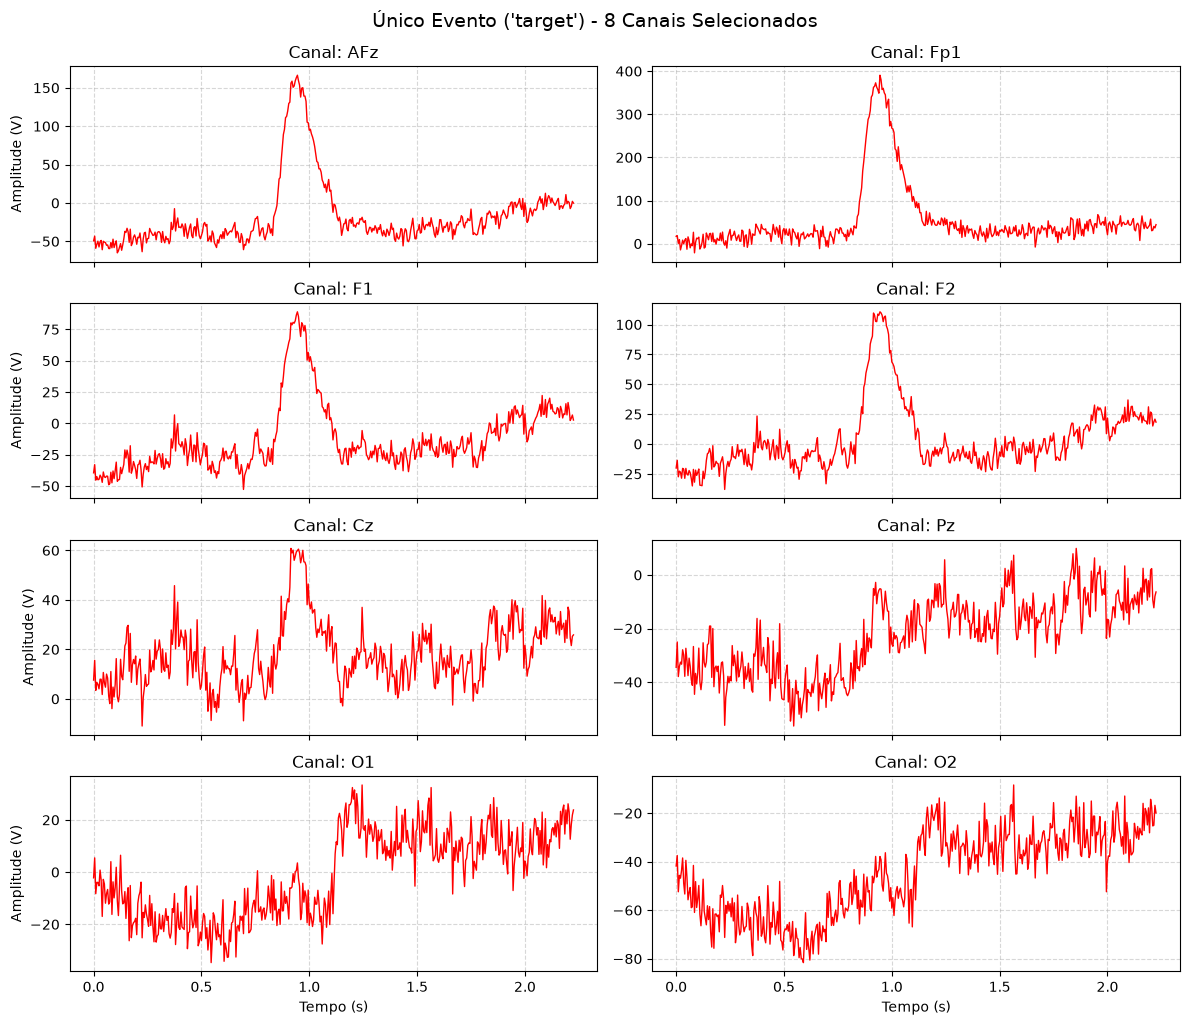

In [6]:
# Obtém uma época da classe 'target'
single_epoch = epochs["target"][1]

plots_evoked(single_epoch)

Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 661 samples (3.305 s)



C:\Users\pborn\AppData\Local\Temp\ipykernel_30072\3170075039.py:5: RuntimeWarning: filter_length (661) is longer than the signal (446), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filtrado.filter(l_freq=1.0, h_freq=30.0)


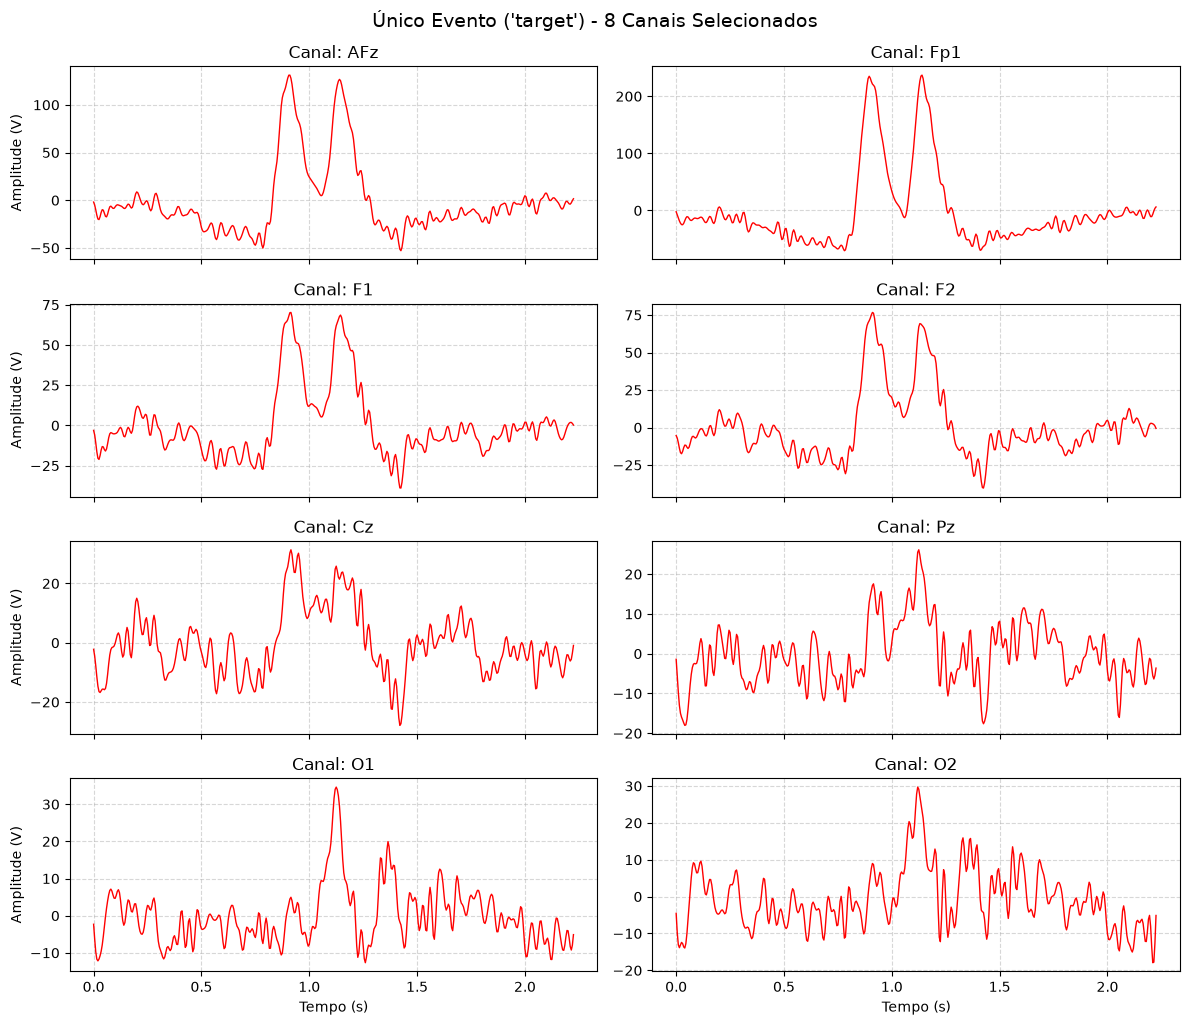

In [7]:
epochs_filtrado = epochs.copy()

# Aplica filtro passa-banda típico para análise espectral de ondas cerebrais (ex: 1 a 30 Hz ou 4 a 30 Hz)
# e remove ruído de rede elétrica (60 Hz no Brasil / 50 Hz em datasets europeus/asiáticos)
epochs_filtrado.filter(l_freq=1.0, h_freq=30.0)

# Plota a mesma época após o filtro para comparar o antes e o depois
single_epoch_filtrada = epochs_filtrado["target"][0]
plots_evoked(single_epoch_filtrada)